# Machine Learning
Reviewed version of the supplied IBM lab. See README and reports/validation.md for execution evidence and limitations.
Run with the working directory set to notebooks/. Local course snapshots are independent of live API/web-scraping outputs.


## Evaluation scope
This is a retrospective educational benchmark, with a random stratified holdout. Features such as ReusedCount, Flights and booster identity require a separate point-in-time audit before any operational prediction. A temporal evaluation and fold-specific feature engineering remain future work. The encoder uses the full course dataset; scaling is fitted only within training folds. Model selection uses training cross-validation, while test scores are descriptive.


> **Completed code edition (2026-11-12).** Original lab tasks have been filled in. Code has been syntax-checked, but the notebook has **not been executed end-to-end** because course datasets / external APIs were unavailable in this environment. Run all cells in Jupyter with network access and inspect the generated results before submission.

<p style="text-align:center">
    <a href="https://skills.network/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMDS0321ENSkillsNetwork26802033-2022-01-01" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo">
    </a>
</p>


# **Space X  Falcon 9 First Stage Landing Prediction**


## Hands on Lab: Complete the Machine Learning Prediction lab


Estimated time needed: **60** minutes


Space X advertises Falcon 9 rocket launches on its website with a cost of 62 million dollars; other providers cost upward of 165 million dollars each, much of the savings is because Space X can reuse the first stage. Therefore if we can determine if the first stage will land, we can determine the cost of a launch. This information can be used if an alternate company wants to bid against space X for a rocket launch.   In this lab, you will create a machine learning pipeline  to predict if the first stage will land given the data from the preceding labs.


![](https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DS0701EN-SkillsNetwork/api/Images/landing_1.gif)


Several examples of an unsuccessful landing are shown here:


![](https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DS0701EN-SkillsNetwork/api/Images/crash.gif)


Most unsuccessful landings are planed. Space X; performs a controlled landing in the oceans.


## Objectives


Perform exploratory  Data Analysis and determine Training Labels

*   create a column for the class
*   Standardize the data
*   Split into training data and test data

\-Find best Hyperparameter for SVM, Classification Trees and Logistic Regression

*   Find the method performs best using test data


## Import Libraries and Define Auxiliary Functions


In [1]:
# Install dependencies once from requirements.txt before running this notebook.

We will import the following libraries for the lab


In [2]:
# Pandas is a software library written for the Python programming language for data manipulation and analysis.
import pandas as pd
# NumPy is a library for the Python programming language, adding support for large, multi-dimensional arrays and matrices, along with a large collection of high-level mathematical functions to operate on these arrays
import numpy as np
# Matplotlib is a plotting library for python and pyplot gives us a MatLab like plotting framework. We will use this in our plotter function to plot data.
import matplotlib.pyplot as plt
#Seaborn is a Python data visualization library based on matplotlib. It provides a high-level interface for drawing attractive and informative statistical graphics
import seaborn as sns
# Preprocessing allows us to standarsize our data
from sklearn import preprocessing
# Allows us to split our data into training and testing data
from sklearn.model_selection import train_test_split
# Allows us to test parameters of classification algorithms and find the best one
from sklearn.model_selection import GridSearchCV
# Logistic Regression classification algorithm
from sklearn.linear_model import LogisticRegression
# Support Vector Machine classification algorithm
from sklearn.svm import SVC
# Decision Tree classification algorithm
from sklearn.tree import DecisionTreeClassifier
# K Nearest Neighbors classification algorithm
from sklearn.neighbors import KNeighborsClassifier

This function is to plot the confusion matrix.


In [3]:
def plot_confusion_matrix(y,y_predict):
    "this function plots the confusion matrix"
    from sklearn.metrics import confusion_matrix

    cm = confusion_matrix(y, y_predict)
    ax= plt.subplot()
    sns.heatmap(cm, annot=True, ax = ax); #annot=True to annotate cells
    ax.set_xlabel('Predicted labels')
    ax.set_ylabel('True labels')
    ax.set_title('Confusion Matrix'); 
    ax.xaxis.set_ticklabels(['did not land', 'land']); ax.yaxis.set_ticklabels(['did not land', 'landed']) 
    plt.show() 

## Load the dataframe


Load the data


In [4]:
data = pd.read_csv('../data/dataset_part_2.csv')

In [5]:
data.head()

Out[5]: 
   FlightNumber        Date BoosterVersion  ...   Longitude   Latitude  Class
0             1  2010-06-04       Falcon 9  ...  -80.577366  28.561857      0
1             2  2012-05-22       Falcon 9  ...  -80.577366  28.561857      0
2             3  2013-03-01       Falcon 9  ...  -80.577366  28.561857      0
3             4  2013-09-29       Falcon 9  ... -120.610829  34.632093      0
4             5  2013-12-03       Falcon 9  ...  -80.577366  28.561857      0

[5 rows x 18 columns]


In [6]:

X = pd.read_csv('../data/dataset_part_3.csv')

In [7]:
X.head(100)

Out[7]: 
    FlightNumber   PayloadMass  ...  Serial_B1060  Serial_B1062
0            1.0   6104.959412  ...           0.0           0.0
1            2.0    525.000000  ...           0.0           0.0
2            3.0    677.000000  ...           0.0           0.0
3            4.0    500.000000  ...           0.0           0.0
4            5.0   3170.000000  ...           0.0           0.0
..           ...           ...  ...           ...           ...
85          86.0  15400.000000  ...           1.0           0.0
86          87.0  15400.000000  ...           0.0           0.0
87          88.0  15400.000000  ...           0.0           0.0
88          89.0  15400.000000  ...           1.0           0.0
89          90.0   3681.000000  ...           0.0           1.0

[90 rows x 80 columns]


## TASK  1


Create a NumPy array from the column <code>Class</code> in <code>data</code>, by applying the method <code>to_numpy()</code>  then
assign it  to the variable <code>Y</code>,make sure the output is a  Pandas series (only one bracket df\['name of  column']).


In [8]:
Y = data['Class'].to_numpy()
print('Target shape:', Y.shape)

Target shape: (90,)


## TASK  2


Standardize the data in <code>X</code> then reassign it to the variable  <code>X</code> using the transform provided below.


In [9]:
# students get this 
transform = preprocessing.StandardScaler()

We split the data into training and testing data using the  function  <code>train_test_split</code>.   The training data is divided into validation data, a second set used for training  data; then the models are trained and hyperparameters are selected using the function <code>GridSearchCV</code>.


## TASK  3


Use the function train_test_split to split the data X and Y into training and test data. Set the parameter test_size to  0.2 and random_state to 2. The training data and test data should be assigned to the following labels.


<code>X_train, X_test, Y_train, Y_test</code>


In [10]:
assert len(X) == len(Y) and not X.isna().any().any()
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=2, stratify=Y)
print('Train/test records:', len(X_train), len(X_test))
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=2)
def tune(model, parameters):
    pipeline = Pipeline([('scaler', preprocessing.StandardScaler()), ('model', model)])
    return GridSearchCV(pipeline, {'model__' + k: v for k, v in parameters.items()}, cv=cv, scoring='accuracy', n_jobs=1, error_score='raise')

Train/test records: 72 18


we can see we only have 18 test samples.


In [11]:
Y_test.shape

Out[11]: (18,)


## TASK  4


Create a logistic regression object  then create a  GridSearchCV object  <code>logreg_cv</code> with cv = 10.  Fit the object to find the best parameters from the dictionary <code>parameters</code>.


In [12]:
parameters ={'C':[0.01,0.1,1],
             
             'solver':['lbfgs']}

In [13]:
parameters ={"C":[0.01,0.1,1], 'solver':['lbfgs']}# l1 lasso l2 ridge
lr=LogisticRegression(max_iter=2000)

logreg_cv = tune(lr, parameters)
logreg_cv.fit(X_train, Y_train)

Out[13]: 
GridSearchCV(cv=StratifiedKFold(n_splits=10, random_state=2, shuffle=True),
             error_score='raise',
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('model',
                                        LogisticRegression(max_iter=2000))]),
             n_jobs=1,
             param_grid={'model__C': [0.01, 0.1, 1],
                         'model__solver': ['lbfgs']},
             scoring='accuracy')


We output the <code>GridSearchCV</code> object for logistic regression. We display the best parameters using the data attribute <code>best_params\_</code> and the accuracy on the validation data using the data attribute <code>best_score\_</code>.


In [14]:
print("tuned hpyerparameters :(best parameters) ",logreg_cv.best_params_)
print("accuracy :",logreg_cv.best_score_)

tuned hpyerparameters :(best parameters)  {'model__C': 0.1, 'model__solver': 'lbfgs'}
accuracy : 0.8339285714285716


## TASK  5


Calculate the accuracy on the test data using the method <code>score</code>:


In [15]:
print('Logistic regression test accuracy:', logreg_cv.score(X_test, Y_test))

Logistic regression test accuracy: 0.7777777777777778


Lets look at the confusion matrix:


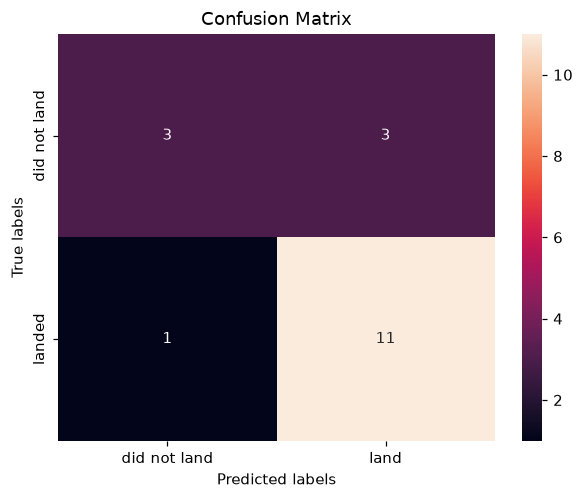

In [16]:
yhat=logreg_cv.predict(X_test)
plot_confusion_matrix(Y_test,yhat)

Examining the confusion matrix, we see that logistic regression can distinguish between the different classes.  We see that the problem is false positives.

Overview:

True Postive - 12 (True label is landed, Predicted label is also landed)

False Postive - 3 (True label is not landed, Predicted label is landed)


## TASK  6


Create a support vector machine object then  create a  <code>GridSearchCV</code> object  <code>svm_cv</code> with cv = 10.  Fit the object to find the best parameters from the dictionary <code>parameters</code>.


In [17]:
parameters = {'kernel':('linear', 'rbf','poly', 'sigmoid'),
              'C': np.logspace(-3, 3, 5),
              'gamma':np.logspace(-3, 3, 5)}
svm = SVC()

In [18]:
svm_cv = tune(svm, parameters)
svm_cv.fit(X_train, Y_train)

Out[18]: 
GridSearchCV(cv=StratifiedKFold(n_splits=10, random_state=2, shuffle=True),
             error_score='raise',
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('model', SVC())]),
             n_jobs=1,
             param_grid={'model__C': array([1.00000000e-03, 3.16227766e-02, 1.00000000e+00, 3.16227766e+01,
       1.00000000e+03]),
                         'model__gamma': array([1.00000000e-03, 3.16227766e-02, 1.00000000e+00, 3.16227766e+01,
       1.00000000e+03]),
                         'model__kernel': ('linear', 'rbf', 'poly', 'sigmoid')},
             scoring='accuracy')


In [19]:
print("tuned hpyerparameters :(best parameters) ",svm_cv.best_params_)
print("accuracy :",svm_cv.best_score_)

tuned hpyerparameters :(best parameters)  {'model__C': np.float64(1.0), 'model__gamma': np.float64(0.03162277660168379), 'model__kernel': 'sigmoid'}
accuracy : 0.8625


## TASK  7


Calculate the accuracy on the test data using the method <code>score</code>:


In [20]:
print('SVM test accuracy:', svm_cv.score(X_test, Y_test))

SVM test accuracy: 0.8333333333333334


We can plot the confusion matrix


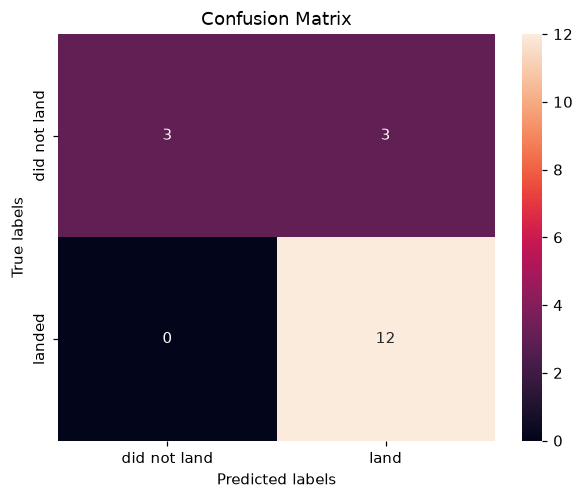

In [21]:
yhat=svm_cv.predict(X_test)
plot_confusion_matrix(Y_test,yhat)

## TASK  8


Create a decision tree classifier object then  create a  <code>GridSearchCV</code> object  <code>tree_cv</code> with cv = 10.  Fit the object to find the best parameters from the dictionary <code>parameters</code>.


In [22]:
parameters = {'criterion': ['gini', 'entropy'],
     'splitter': ['best', 'random'],
     'max_depth': [2*n for n in range(1,10)],
     'max_features': [None, 'sqrt'],
     'min_samples_leaf': [1, 2, 4],
     'min_samples_split': [2, 5, 10]}

tree = DecisionTreeClassifier(random_state=2)

In [23]:
tree_cv = tune(tree, parameters)
tree_cv.fit(X_train, Y_train)

Out[23]: 
GridSearchCV(cv=StratifiedKFold(n_splits=10, random_state=2, shuffle=True),
             error_score='raise',
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('model',
                                        DecisionTreeClassifier(random_state=2))]),
             n_jobs=1,
             param_grid={'model__criterion': ['gini', 'entropy'],
                         'model__max_depth': [2, 4, 6, 8, 10, 12, 14, 16, 18],
                         'model__max_features': [None, 'sqrt'],
                         'model__min_samples_leaf': [1, 2, 4],
                         'model__min_samples_split': [2, 5, 10],
                         'model__splitter': ['best', 'random']},
             scoring='accuracy')


In [24]:
print("tuned hpyerparameters :(best parameters) ",tree_cv.best_params_)
print("accuracy :",tree_cv.best_score_)

tuned hpyerparameters :(best parameters)  {'model__criterion': 'entropy', 'model__max_depth': 2, 'model__max_features': None, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__splitter': 'random'}
accuracy : 0.8892857142857145


## TASK  9


Calculate the accuracy of tree_cv on the test data using the method <code>score</code>:


In [25]:
print('Decision tree test accuracy:', tree_cv.score(X_test, Y_test))

Decision tree test accuracy: 0.8333333333333334


We can plot the confusion matrix


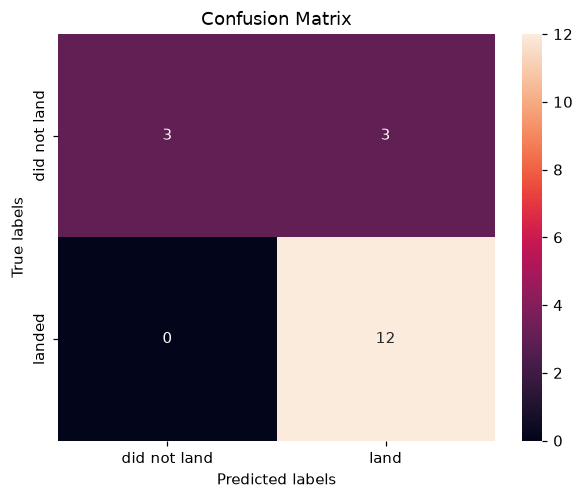

In [26]:
yhat = tree_cv.predict(X_test)
plot_confusion_matrix(Y_test,yhat)

## TASK  10


Create a k nearest neighbors object then  create a  <code>GridSearchCV</code> object  <code>knn_cv</code> with cv = 10.  Fit the object to find the best parameters from the dictionary <code>parameters</code>.


In [27]:
parameters = {'n_neighbors': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
              'algorithm': ['auto', 'ball_tree', 'kd_tree', 'brute'],
              'p': [1,2]}

KNN = KNeighborsClassifier()

In [28]:
knn_cv = tune(KNN, parameters)
knn_cv.fit(X_train, Y_train)

Out[28]: 
GridSearchCV(cv=StratifiedKFold(n_splits=10, random_state=2, shuffle=True),
             error_score='raise',
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('model', KNeighborsClassifier())]),
             n_jobs=1,
             param_grid={'model__algorithm': ['auto', 'ball_tree', 'kd_tree',
                                              'brute'],
                         'model__n_neighbors': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
                         'model__p': [1, 2]},
             scoring='accuracy')


In [29]:
print("tuned hpyerparameters :(best parameters) ",knn_cv.best_params_)
print("accuracy :",knn_cv.best_score_)

tuned hpyerparameters :(best parameters)  {'model__algorithm': 'auto', 'model__n_neighbors': 6, 'model__p': 1}
accuracy : 0.8482142857142858


## TASK  11


Calculate the accuracy of knn_cv on the test data using the method <code>score</code>:


In [30]:
print('KNN test accuracy:', knn_cv.score(X_test, Y_test))

KNN test accuracy: 0.7222222222222222


We can plot the confusion matrix


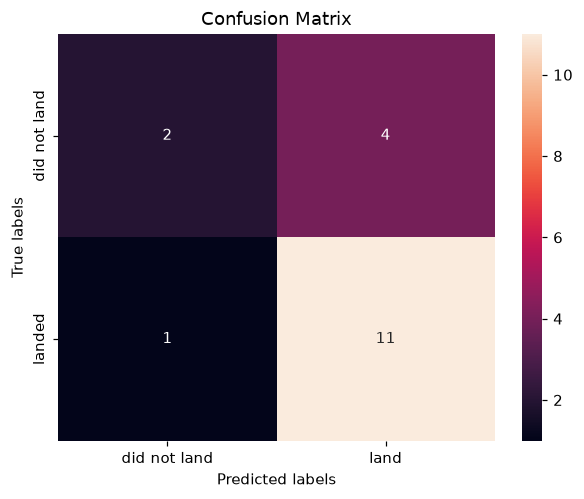

In [31]:
yhat = knn_cv.predict(X_test)
plot_confusion_matrix(Y_test,yhat)

## TASK  12


Find the method performs best:


Model selected by training cross-validation: Decision tree


,Model,Validation accuracy,Test accuracy,Best parameters
2,Decision tree,0.889286,0.833333,"{'model__criterion': 'entropy', 'model__max_de..."
1,SVM,0.862500,0.833333,"{'model__C': np.float64(1.0), 'model__gamma': ..."
3,KNN,0.848214,0.722222,"{'model__algorithm': 'auto', 'model__n_neighbo..."
0,Logistic regression,0.833929,0.777778,"{'model__C': 0.1, 'model__solver': 'lbfgs'}"


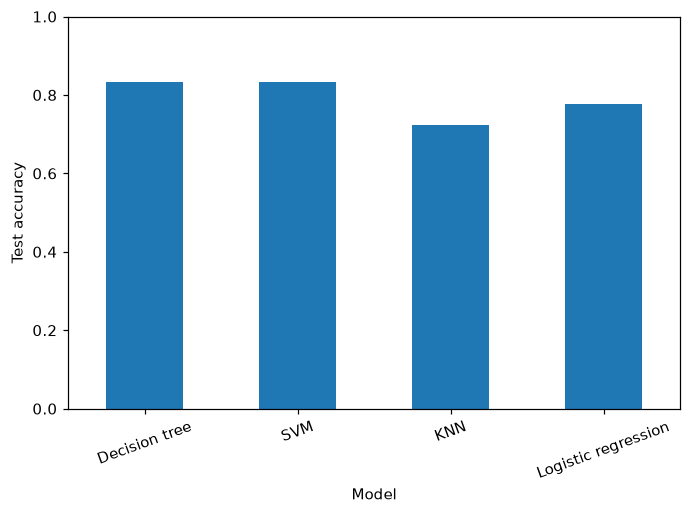

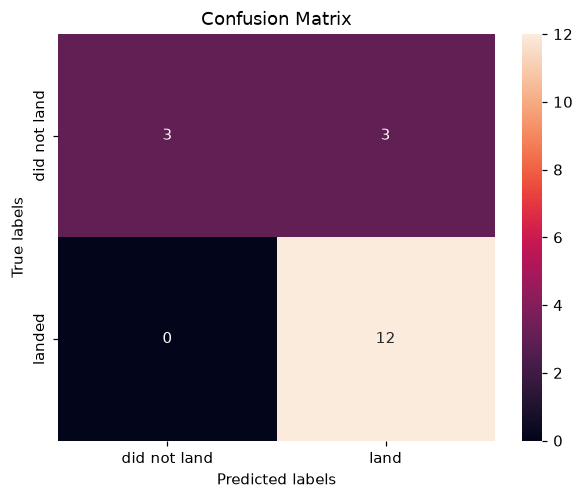

In [32]:
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
models = {'Logistic regression': logreg_cv, 'SVM': svm_cv,
          'Decision tree': tree_cv, 'KNN': knn_cv}
results = pd.DataFrame([
    {'Model': name, 'Validation accuracy': model.best_score_,
     'Test accuracy': accuracy_score(Y_test, model.predict(X_test)),
     'Best parameters': str(model.best_params_)}
    for name, model in models.items()
]).sort_values('Validation accuracy', ascending=False)
display(results)
ax = results.plot.bar(x='Model', y='Test accuracy', ylim=(0, 1), legend=False, rot=20)
ax.set_ylabel('Test accuracy'); plt.tight_layout(); plt.show()
best_name = results.iloc[0]['Model']
print('Model selected by training cross-validation:', best_name)
results.to_csv('../reports/model_scores.csv', index=False)
plot_confusion_matrix(Y_test, models[best_name].predict(X_test))

## Authors


[Pratiksha Verma](https://www.linkedin.com/in/pratiksha-verma-6487561b1/)


<!--## Change Log--!>


<!--| Date (YYYY-MM-DD) | Version | Changed By      | Change Description      |
| ----------------- | ------- | -------------   | ----------------------- |
| 2022-11-09        | 1.0     | Pratiksha Verma | Converted initial version to Jupyterlite|--!>


### <h3 align="center"> IBM Corporation 2022. All rights reserved. <h3/>
